<a href="https://colab.research.google.com/github/luka4-lab/linear-Regression/blob/main/linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
from google.colab import files
uploaded = files.upload()

Saving bsas_realstate_on_sale_properati_dataset_2020.csv to bsas_realstate_on_sale_properati_dataset_2020.csv


In [87]:

def wrangle(filepath):
    # Load dataset
    df = pd.read_csv(filepath)

    # Rename l2 to parent_place_with_names
    df.rename(
        columns={"l2": "parent_place_with_names"},
        inplace=True
    )

    # Select properties in Capital Federal
    mask_ba = df["parent_place_with_names"].str.contains(
        "Capital Federal", na=False
    )

    # Select apartments
    mask_dep = df["property_type"] == "Departamento"
    # subset the property based on price that is less than 400_000
    mask_price=df["price"]<400_000
    # remove the outlier
    low,high=df["surface_covered"].quantile([0.1,0.9])
    mask_surface=df["surface_covered"].between(low,high)

    # Apply both conditions
    df = df[mask_ba & mask_dep & mask_price& mask_surface]

    return df


In [88]:

df = wrangle(
    "/content/bsas_realstate_on_sale_properati_dataset_2020.csv"
)

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (51670, 19)


,start_date,end_date,created_on,lat,lon,l1,parent_place_with_names,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,price,currency,title,description,property_type,operation_type
0,2019-10-17,2019-12-23,2019-10-17,-34.605880,-58.384949,Argentina,Capital Federal,San Cristobal,7.0,7.0,2.0,140.0,140.0,153000.0,USD,"***Venta semipiso centro, ideal hostel*****",DESCRIPCION DE LA PROPIEDAD: Departamento de 1...,Departamento,Venta
11,2019-10-17,2019-10-26,2019-10-17,-34.603683,-58.381557,Argentina,Capital Federal,Boedo,2.0,1.0,1.0,68.0,59.0,149000.0,USD,Venta Departamento en Boedo Capital Federal Ga...,"Departamento en Venta, 2 ambientes espectacula...",Departamento,Venta
12,2019-10-17,2019-12-19,2019-10-17,-34.630349,-58.417223,Argentina,Capital Federal,Boedo,2.0,1.0,1.0,50.0,44.0,115000.0,USD,Departamento dos ambientes tipo duplex - Venta...,"Amplio dos ambientes en duplex, 7 años de anti...",Departamento,Venta
22,2019-10-17,2019-11-13,2019-10-17,-34.626240,-58.462078,Argentina,Capital Federal,Flores,2.0,1.0,1.0,45.0,45.0,95000.0,USD,Listo para mudarte- Excelente 2 ambientes ampl...,Inmejorable ubicación a tan solo 2 cuadras del...,Departamento,Venta
23,2019-10-17,2019-12-23,2019-10-17,-34.625611,-58.462403,Argentina,Capital Federal,Flores,2.0,1.0,1.0,45.0,45.0,95000.0,USD,Venta. Departamento 2 ambientes. Baulera. Exce...,CARACTERÍSTICAS- Ambientes: 2- Superficie Tota...,Departamento,Venta


In [21]:
df["l2"].unique()

array(['Capital Federal', 'Bs.As. G.B.A. Zona Sur',
       'Bs.As. G.B.A. Zona Norte', 'Bs.As. G.B.A. Zona Oeste'],
      dtype=object)

In [23]:
# lets rename l2 to parent_place_with_names
df.rename(columns={"l2":"parent_place_with_names"},inplace=True)
df.head()

,start_date,end_date,created_on,lat,lon,l1,parent_place_with_names,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,price,currency,title,description,property_type,operation_type
0,2019-10-17,2019-12-23,2019-10-17,-34.605880,-58.384949,Argentina,Capital Federal,San Cristobal,7.0,7.0,2.0,140.0,140.0,153000.0,USD,"***Venta semipiso centro, ideal hostel*****",DESCRIPCION DE LA PROPIEDAD: Departamento de 1...,Departamento,Venta
1,2019-10-17,2019-11-21,2019-10-17,-34.624056,-58.412110,Argentina,Capital Federal,Boedo,2.0,1.0,2.0,70.0,58.0,159000.0,USD,Espectacular PH reciclado en Boedo sin expensas.,PH reciclado en Boedo a una cuadra de la plaz...,PH,Venta
2,2019-10-17,2019-11-01,2019-10-17,-34.593569,-58.427474,Argentina,Capital Federal,Palermo,2.0,1.0,1.0,45.0,45.0,125000.0,USD,Depto.tipo casa de 2 ambientes en Venta en Pal...,"2 ambienets amplio , excelente estado , patio ...",PH,Venta
3,2019-10-17,2019-12-23,2019-10-17,-34.581294,-58.436754,Argentina,Capital Federal,Palermo,2.0,1.0,1.0,85.0,50.0,295000.0,USD,COSTA RICA 5800 / PALERMO HOLLYWOOD / VENTA PH...,HERMOSO PH EN PALERMO!!!2 AMBIENTES TOTALMENTE...,PH,Venta
4,2019-10-17,2020-03-11,2019-10-17,-34.914194,-57.938219,Argentina,Bs.As. G.B.A. Zona Sur,La Plata,2.0,1.0,1.0,50.0,35.0,40000.0,USD,58 entre 1 y 2 Venta de departamento en ph.1 ...,58 entre 1 y 2 Venta de departamento en PH. P...,PH,Venta


In [25]:
# lets subset to properties in capital federal
mask_ba = df["parent_place_with_names"].str.contains("Capital Federal")
df[mask_ba].head()

,start_date,end_date,created_on,lat,lon,l1,parent_place_with_names,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,price,currency,title,description,property_type,operation_type
0,2019-10-17,2019-12-23,2019-10-17,-34.605880,-58.384949,Argentina,Capital Federal,San Cristobal,7.0,7.0,2.0,140.0,140.0,153000.0,USD,"***Venta semipiso centro, ideal hostel*****",DESCRIPCION DE LA PROPIEDAD: Departamento de 1...,Departamento,Venta
1,2019-10-17,2019-11-21,2019-10-17,-34.624056,-58.412110,Argentina,Capital Federal,Boedo,2.0,1.0,2.0,70.0,58.0,159000.0,USD,Espectacular PH reciclado en Boedo sin expensas.,PH reciclado en Boedo a una cuadra de la plaz...,PH,Venta
2,2019-10-17,2019-11-01,2019-10-17,-34.593569,-58.427474,Argentina,Capital Federal,Palermo,2.0,1.0,1.0,45.0,45.0,125000.0,USD,Depto.tipo casa de 2 ambientes en Venta en Pal...,"2 ambienets amplio , excelente estado , patio ...",PH,Venta
3,2019-10-17,2019-12-23,2019-10-17,-34.581294,-58.436754,Argentina,Capital Federal,Palermo,2.0,1.0,1.0,85.0,50.0,295000.0,USD,COSTA RICA 5800 / PALERMO HOLLYWOOD / VENTA PH...,HERMOSO PH EN PALERMO!!!2 AMBIENTES TOTALMENTE...,PH,Venta
5,2019-10-17,2019-11-01,2019-10-17,-34.593779,-58.441239,Argentina,Capital Federal,Villa Crespo,2.0,1.0,1.0,56.0,56.0,150000.0,USD,Depto.tipo casa de 2 ambientes en Venta en Vil...,"Excelente ph solo 2 unidades, no paga expensas...",PH,Venta


In [18]:
df["property_type"].unique()

array(['Departamento', 'PH', 'Casa', 'Lote', 'Casa de campo', 'Oficina',
       'Otro', 'Local comercial', 'Cochera', 'Depósito'], dtype=object)

In [29]:
# subset to departamento
msk_dep = df["property_type"] == "Departamento"
df[msk_dep].head()

,start_date,end_date,created_on,lat,lon,l1,l2,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,price,currency,title,description,property_type,operation_type
0,2019-10-17,2019-12-23,2019-10-17,-34.605880,-58.384949,Argentina,Capital Federal,San Cristobal,7.0,7.0,2.0,140.0,140.0,153000.0,USD,"***Venta semipiso centro, ideal hostel*****",DESCRIPCION DE LA PROPIEDAD: Departamento de 1...,Departamento,Venta
11,2019-10-17,2019-10-26,2019-10-17,-34.603683,-58.381557,Argentina,Capital Federal,Boedo,2.0,1.0,1.0,68.0,59.0,149000.0,USD,Venta Departamento en Boedo Capital Federal Ga...,"Departamento en Venta, 2 ambientes espectacula...",Departamento,Venta
12,2019-10-17,2019-12-19,2019-10-17,-34.630349,-58.417223,Argentina,Capital Federal,Boedo,2.0,1.0,1.0,50.0,44.0,115000.0,USD,Departamento dos ambientes tipo duplex - Venta...,"Amplio dos ambientes en duplex, 7 años de anti...",Departamento,Venta
13,2019-10-17,2019-11-30,2019-10-17,-34.545990,-58.859357,Argentina,Bs.As. G.B.A. Zona Norte,Pilar,1.0,1.0,1.0,50.0,35.0,45000.0,USD,Monoambiente con cochera en Boca Ratón. Oportu...,"Departamento monoambiente muy luminoso, impeca...",Departamento,Venta
14,2019-10-17,2019-12-23,2019-10-17,-34.452861,-58.898987,Argentina,Bs.As. G.B.A. Zona Norte,Pilar,1.0,1.0,1.0,32.0,32.0,35000.0,USD,Monoambiente en Pilar con amenities. Anticipo ...,Boutique Pilar es un desarrollo inmobiliario c...,Departamento,Venta


In [46]:
df["price"].unique()

array([153000., 149000., 115000., ..., 237677., 266647., 262415.],
      shape=(5126,))

In [54]:
# Check all unique currency values and their frequencies
print("Unique Currencies:")
print(df['currency'].unique())

print("\nCurrency Counts:")
print(df['currency'].value_counts(dropna=False))

Unique Currencies:
['USD']

Currency Counts:
currency
USD    68963
Name: count, dtype: int64


In [56]:
# subset property based on price that is less than 400_000 usd dollars
mask_price = df["price"] < 400_000
df[mask_price].head()

,start_date,end_date,created_on,lat,lon,l1,parent_place_with_names,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,price,currency,title,description,property_type,operation_type
0,2019-10-17,2019-12-23,2019-10-17,-34.605880,-58.384949,Argentina,Capital Federal,San Cristobal,7.0,7.0,2.0,140.0,140.0,153000.0,USD,"***Venta semipiso centro, ideal hostel*****",DESCRIPCION DE LA PROPIEDAD: Departamento de 1...,Departamento,Venta
11,2019-10-17,2019-10-26,2019-10-17,-34.603683,-58.381557,Argentina,Capital Federal,Boedo,2.0,1.0,1.0,68.0,59.0,149000.0,USD,Venta Departamento en Boedo Capital Federal Ga...,"Departamento en Venta, 2 ambientes espectacula...",Departamento,Venta
12,2019-10-17,2019-12-19,2019-10-17,-34.630349,-58.417223,Argentina,Capital Federal,Boedo,2.0,1.0,1.0,50.0,44.0,115000.0,USD,Departamento dos ambientes tipo duplex - Venta...,"Amplio dos ambientes en duplex, 7 años de anti...",Departamento,Venta
20,2019-10-17,2019-10-24,2019-10-17,-34.608246,-58.444262,Argentina,Capital Federal,Abasto,2.0,1.0,1.0,31.0,31.0,75000.0,USD,Departamento de 2 ambientes en Venta en Abasto,"Lindo monoambiente duplex, 31 m2, living-comed...",Departamento,Venta
21,2019-10-17,2019-10-28,2019-10-17,-34.603890,-58.410998,Argentina,Capital Federal,Abasto,1.0,1.0,1.0,22.0,22.0,48000.0,USD,Monoambiente Vista Abierta,Excelente Inversion o 1era vivienda en renovad...,Departamento,Venta


Explore
#Create a histogram of "surface_covered". Make sure that the x-axis has the label "Area [sq meters]" and the plot has the title "Distribution of Apartment Sizes"

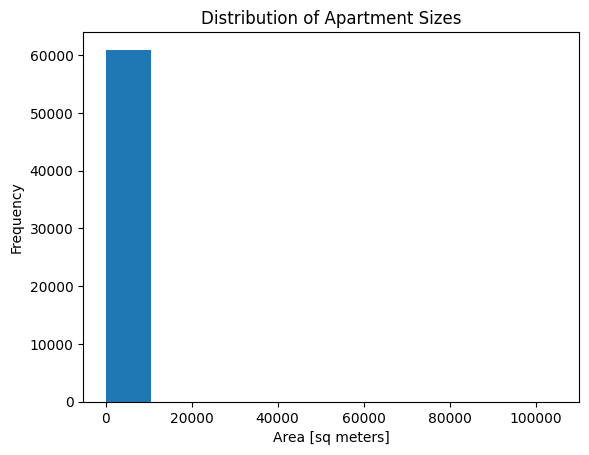

In [62]:
import matplotlib.pyplot as plt

# Correct the column name to 'surface_covered'
plt.hist(df["surface_covered"])
plt.xlabel("Area [sq meters]")
plt.ylabel("Frequency")
plt.title("Distribution of Apartment Sizes")
plt.show();

! When you see a histogram like the one above, it suggests that there are outliers in your dataset. This can affect model performance — especially in the sorts of linear models

In [64]:
# LETS IDENTIFY THE OUTLIERS USING THE SUMMARY STATISTICS
df.describe()["surface_covered"]

,surface_covered
count,60935.000000
mean,71.499286
std,519.893191
min,1.000000
25%,41.000000
50%,54.000000
75%,74.000000
max,104890.000000


he mean (71.5) is much higher than the median (54), and the maximum is 104,890.

This suggests that your column may contain extreme outlier

In [66]:
# remove the outliers
df["surface_covered"].quantile([0.1,0.9])


,surface_covered
0.1,34.0
0.9,97.0


In [68]:
low, high = df["surface_covered"].quantile([0.1, 0.9])
mask_surface = df["surface_covered"].between(low, high)
df[mask_surface].head()

,start_date,end_date,created_on,lat,lon,l1,parent_place_with_names,l3,rooms,bedrooms,bathrooms,surface_total,surface_covered,price,currency,title,description,property_type,operation_type
11,2019-10-17,2019-10-26,2019-10-17,-34.603683,-58.381557,Argentina,Capital Federal,Boedo,2.0,1.0,1.0,68.0,59.0,149000.0,USD,Venta Departamento en Boedo Capital Federal Ga...,"Departamento en Venta, 2 ambientes espectacula...",Departamento,Venta
12,2019-10-17,2019-12-19,2019-10-17,-34.630349,-58.417223,Argentina,Capital Federal,Boedo,2.0,1.0,1.0,50.0,44.0,115000.0,USD,Departamento dos ambientes tipo duplex - Venta...,"Amplio dos ambientes en duplex, 7 años de anti...",Departamento,Venta
22,2019-10-17,2019-11-13,2019-10-17,-34.626240,-58.462078,Argentina,Capital Federal,Flores,2.0,1.0,1.0,45.0,45.0,95000.0,USD,Listo para mudarte- Excelente 2 ambientes ampl...,Inmejorable ubicación a tan solo 2 cuadras del...,Departamento,Venta
23,2019-10-17,2019-12-23,2019-10-17,-34.625611,-58.462403,Argentina,Capital Federal,Flores,2.0,1.0,1.0,45.0,45.0,95000.0,USD,Venta. Departamento 2 ambientes. Baulera. Exce...,CARACTERÍSTICAS- Ambientes: 2- Superficie Tota...,Departamento,Venta
24,2019-10-17,2019-12-23,2019-10-17,-34.636661,-58.471170,Argentina,Capital Federal,Flores,2.0,1.0,1.0,58.0,48.0,154000.0,USD,VENTA - 2 AMBIENTES A ESTRENAR CON BALCÓN - F...,******ESPECTACULAR DOS AMBIENTES A LA VENTA A ...,Departamento,Venta


Create a scatter plot that shows price ("price") vs area ("surface_covered") in our dataset. Make sure to label your x-axis "Area [sq meters]" and your y-axis "Price [USD]"

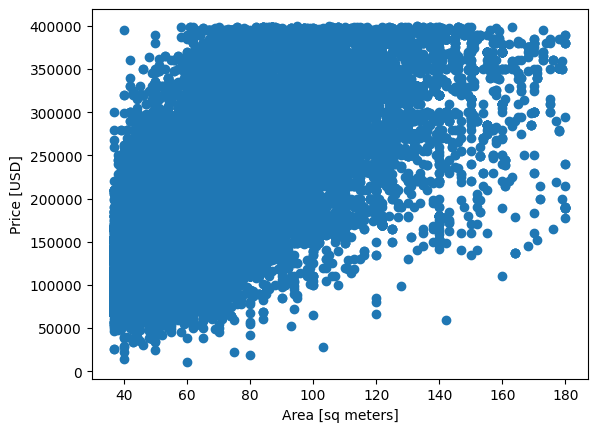

In [91]:
plt.scatter(x=df["surface_covered"], y=df["price"])
plt.xlabel("Area [sq meters]")
plt.ylabel("Price [USD]")
plt.show();

Positive relationship

Generally, as apartment size increases, the price also tends to increase.

In [93]:
#split
# create our feature matrix (X)  these are what our model will look at to do the preditcion
feature=["surface_covered"]
X_train=df[feature]
X_train.shape

(51670, 1)

In [95]:
#create our target  matrix i what our model is going to predict
target="price"
y_train=df[target]
y_train.shape

(51670,)

In [97]:
#build the model
# create baseline its  A baseline gives us an idea of how well our model needs to perform to be useful to our stakeholders.
# calculate the mean for traget
y_mean=y_train.mean()
y_mean


np.float64(189679.63715889296)

: Add a line to the plot below that shows the relationship between the observations X_train and our dumb model's predictions y_pred_baseline. Be sure that the line color is orange, and that it has the label "Baseline Model".

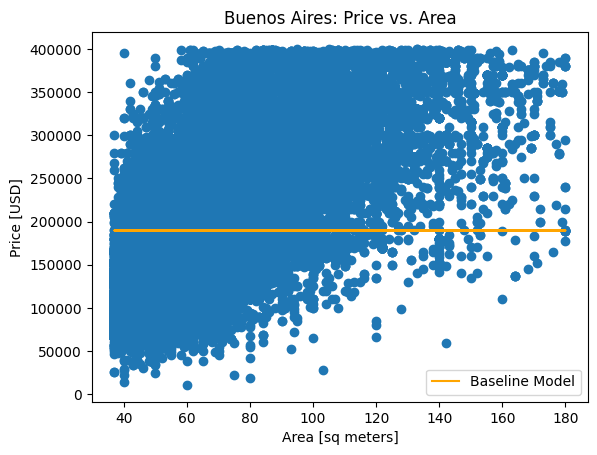

In [106]:
#calculate the baseline prediction list
y_pred_baseline = [y_mean] * len(y_train)

# Correctly plot the baseline orange line and the scatter plot
plt.plot(X_train["surface_covered"], y_pred_baseline, color="orange", label="Baseline Model")
plt.scatter(X_train, y_train)
plt.xlabel("Area [sq meters]")
plt.ylabel("Price [USD]")
plt.title("Buenos Aires: Price vs. Area")
plt.legend();

Looking at this visualization, it seems like our baseline model doesn't really follow the trend in the data. But, as a data scientist, you can't depend only on a subjective plot to evaluate a model. You need an exact, mathematically calculate performance metric. There are lots of performance metrics, but the one we'll use here is the mean absolute error.

In [108]:
#In simple terms, it measures how wrong our model is when predicting apartment prices.
from sklearn.metrics import mean_absolute_error
mae_baseline=mean_absolute_error(y_train,y_pred_baseline)

print("Mean apt price", round(y_mean, 2))
print("Baseline MAE:", round(mae_baseline, 2))

Mean apt price 189679.64
Baseline MAE: 62904.71


Linear regression is a machine learning method that helps us predict a number by looking at the relationship between different variables.In the simplest words:

Linear regression teaches a computer to draw the best-fitting straight line through data so it can predict a numerical value.

In [110]:
#iterate

#initiate the Linear Regression
from sklearn.linear_model import LinearRegression
model=LinearRegression()

In [112]:
# fit our mmode that is our traget and feature matrix
model.fit(X_train,y_train)

LinearRegression()

In [114]:
from sklearn.utils.validation import check_is_fitted
check_is_fitted(model)

In [116]:
#evaluate our model
# by first seeing it how it performs when making prediction
y_pred_training = model.predict(X_train)
y_pred_training[:5]

array([353507.30335521, 175931.71855656, 143047.35100125, 145239.6421716 ,
       145239.6421716 ])

In [118]:
mae_training=mean_absolute_error(y_train,y_pred_trainingp)
print("Training MAE:", round(mae_training, 2))

Training MAE: 41820.79


In [123]:
!find /content/worldquant -iname "*buenos-aires-test-features.csv"